# World model d'une balle rebondissante.

# Étape 2 : la balle pilotable

## Objectif
À l'étape 1, le modèle prédisait le mouvement d'une balle qu'il ne pouvait qu'observer.
Ici, un agent peut agir sur la balle en lui donnant une petite poussée à chaque pas.
On apprend un modèle qui prédit l'effet de ces actions, puis on l'utilise pour **planifier** :
amener la balle vers une cible en imaginant les conséquences de différentes suites d'actions.

## Critères de réussite
- **Modèle** : il prédit le déplacement suivant mieux que la baseline « dernier déplacement + action »,
  en particulier autour des rebonds, sur des trajectoires jamais vues.
- **Planification** : l'agent qui planifie avec le modèle atteint la cible nettement plus souvent
  qu'une politique aléatoire, et s'approche des performances obtenues en planifiant avec le vrai
  simulateur.

In [ ]:
import random

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Simulation ---
N_TRAJ = 500        # nombre de trajectoires
N_STEPS = 200       # positions par trajectoire
A_MAX = 0.005       # amplitude maximale d'une action, par composante
V_MAX = 0.05        # vitesse maximale, par composante
V_INIT = 0.03       # norme de la vitesse initiale

# --- Modèle ---
K = 3               # taille du contexte

In [ ]:
def simulate_controlled_ball(rng, n_steps, v_init, a_max, v_max, box=(0.0, 1.0)):
    """
    Simule une balle pilotée par des poussées aléatoires dans une boîte carrée,
    avec rebonds élastiques sur les murs.

    Paramètres
    ----------
    rng : np.random.Generator
        Générateur aléatoire partagé.
    n_steps : int
        Nombre de positions dans la trajectoire.
    v_init : float
        Norme de la vitesse initiale.
    a_max : float
        Amplitude maximale d'une action, par composante.
    v_max : float
        Vitesse maximale, par composante.
    box : tuple
        Limites (min, max) de la boîte, identiques sur les deux axes.

    Sorties
    -------
    positions : np.ndarray de forme (n_steps, 2)
    actions : np.ndarray de forme (n_steps - 1, 2)
        actions[t-1] est l'action qui fait passer de positions[t-1] à positions[t].
    bounces : np.ndarray de forme (n_steps,), booléens
        bounces[t] vaut True si un rebond a eu lieu entre les pas t-1 et t.
    """
    low, high = box
    margin = 0.1 * (high - low)

    # Tableaux créés à l'avance : leurs tailles sont garanties
    positions = np.zeros((n_steps, 2))
    actions = np.zeros((n_steps - 1, 2))
    bounces = np.zeros(n_steps, dtype=bool)

    # Position et direction de départ aléatoires
    pos = rng.uniform(low + margin, high - margin, size=2)
    angle = rng.uniform(0.0, 2.0 * np.pi)
    velocity = v_init * np.array([np.cos(angle), np.sin(angle)])
    positions[0] = pos

    for t in range(1, n_steps):

        action = rng.uniform(-a_max, a_max, size=2) # Action aléatoire : une petite poussée sur chaque axe

        velocity = velocity + action   # La poussée modifie la vitesse

        speed = np.linalg.norm(velocity)
        if speed > v_max:
            velocity = velocity * (v_max / speed)   # même direction, norme ramenée à v_max   # La vitesse est limitée sur chaque axe

        pos = pos + velocity  # Déplacement en ligne droite

        for d in range(2):    # Rebonds, axe par axe (d = 0 pour x, d = 1 pour y)
            if pos[d] < low:
                pos[d] = 2 * low - pos[d]       # réflexion à l'intérieur de la boîte
                velocity[d] *= -1               # inversion de la vitesse sur cet axe
                bounces[t] = True
            elif pos[d] > high:
                pos[d] = 2 * high - pos[d]
                velocity[d] *= -1
                bounces[t] = True

        # 6. Enregistrement
        positions[t] = pos
        actions[t - 1] = action

    return positions, actions, bounces

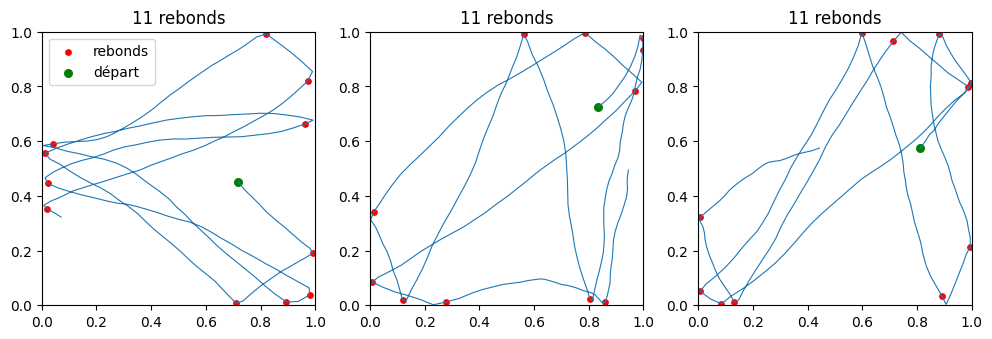

Formes : (200, 2) (199, 2) (200,)
Positions dans la boîte : True True
Vitesse max observée : 0.046865254507060805 (limite : 0.05 )


In [ ]:
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax in axes:
    positions, actions, bounces = simulate_controlled_ball(rng, N_STEPS, V_INIT, A_MAX, V_MAX)
    ax.plot(positions[:, 0], positions[:, 1], lw=0.8)
    ax.scatter(*positions[bounces].T, c="red", s=15, label="rebonds")
    ax.scatter(*positions[0], c="green", s=30, label="départ")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_title(f"{bounces.sum()} rebonds")
axes[0].legend()
plt.show()

# Contrôles numériques sur la dernière trajectoire
displacements = np.diff(positions, axis=0)
print("Formes :", positions.shape, actions.shape, bounces.shape)
print("Positions dans la boîte :", positions.min() >= 0, positions.max() <= 1)
print("Vitesse max observée :", np.abs(displacements).max(), "(limite :", V_MAX, ")")

In [ ]:
print("Vitesse max observée :", np.linalg.norm(displacements, axis=1).max(), "(limite :", V_MAX, ")")

Vitesse max observée : 0.05 (limite : 0.05 )


In [ ]:
def make_examples(positions, actions, bounces, k=3):
    """
    Transforme une trajectoire pilotée en exemples (contexte + action, déplacement suivant).

    Pour chaque instant t :
    - entrée : positions p(t-k+1), ..., p(t) aplaties, suivies de l'action actions[t] ;
    - cible : déplacement p(t+1) - p(t) ;
    - near_bounce : True si un rebond a lieu entre p(t-k+1) et p(t+1).
    """
    X, Y, near_bounce = [], [], []
    for t in range(k - 1, len(positions) - 1):
        context = positions[t - k + 1 : t + 1].flatten()   # k positions → 2k nombres
        action = actions[t]                                # action appliquée entre p(t) et p(t+1)

        X.append(np.concatenate([context, action]))        # entrée : 2k + 2 nombres
        Y.append(positions[t + 1] - positions[t])
        near_bounce.append(bounces[t - k + 2 : t + 2].any())

    return np.array(X), np.array(Y), np.array(near_bounce)

In [ ]:
rng = np.random.default_rng(SEED)
trajectories = [simulate_controlled_ball(rng, N_STEPS, V_INIT, A_MAX, V_MAX) for _ in range(N_TRAJ)]

# Séparation PAR TRAJECTOIRE : 80 % entraînement, 10 % validation, 10 % test
indices = rng.permutation(N_TRAJ)
n_train, n_val = int(0.8 * N_TRAJ), int(0.1 * N_TRAJ)
split_indices = {
    "train": indices[:n_train],
    "val": indices[n_train : n_train + n_val],
    "test": indices[n_train + n_val :],
}

def build_split(traj_indices):
    """Construit les exemples de toutes les trajectoires d'un split."""
    parts = [make_examples(*trajectories[i], k=K) for i in traj_indices]
    X = np.concatenate([p[0] for p in parts])
    Y = np.concatenate([p[1] for p in parts])
    near_bounce = np.concatenate([p[2] for p in parts])
    return X, Y, near_bounce

data = {name: build_split(idx) for name, idx in split_indices.items()}

for name, (X, Y, nb) in data.items():
    print(f"{name:5s} : X {X.shape}, Y {Y.shape}, exemples près d'un rebond : {nb.mean():.1%}")

train : X (78800, 8), Y (78800, 2), exemples près d'un rebond : 12.7%
val   : X (9850, 8), Y (9850, 2), exemples près d'un rebond : 12.2%
test  : X (9850, 8), Y (9850, 2), exemples près d'un rebond : 12.5%


In [ ]:
class DynamicsMLP(nn.Module):
    """
    Prédicteur de dynamique : à partir du contexte (positions, et éventuellement l'action),
    prédit le déplacement suivant de la balle. Gère lui-même sa normalisation.
    """

    def __init__(self, n_inputs, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_inputs, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2),
        )
        # Statistiques de normalisation (remplies par fit_normalization)
        self.register_buffer("x_mean", torch.zeros(n_inputs))
        self.register_buffer("x_std", torch.ones(n_inputs))
        self.register_buffer("y_mean", torch.zeros(2))
        self.register_buffer("y_std", torch.ones(2))

    def fit_normalization(self, X_train, Y_train):
        """Calcule les statistiques de normalisation sur le jeu d'entraînement UNIQUEMENT."""
        self.x_mean = torch.as_tensor(X_train.mean(axis=0), dtype=torch.float32)
        self.x_std = torch.as_tensor(X_train.std(axis=0), dtype=torch.float32)
        self.y_mean = torch.as_tensor(Y_train.mean(axis=0), dtype=torch.float32)
        self.y_std = torch.as_tensor(Y_train.std(axis=0), dtype=torch.float32)

    def normalize_x(self, X):
        return (X - self.x_mean) / self.x_std

    def normalize_y(self, Y):
        return (Y - self.y_mean) / self.y_std

    def denormalize_y(self, Y_norm):
        return Y_norm * self.y_std + self.y_mean

    def forward(self, x_norm):
        """Entrée et sortie NORMALISÉES. Utilisé pendant l'entraînement."""
        return self.net(x_norm)

    @torch.no_grad()
    def predict_displacement(self, X):
        """Prédit le déplacement en vraies unités. X : tableau numpy de forme (n, n_inputs)."""
        x = torch.as_tensor(X, dtype=torch.float32)
        return self.denormalize_y(self.forward(self.normalize_x(x))).numpy()

In [ ]:
X_train, Y_train, _ = data["train"]
X_val, Y_val, nb_val = data["val"]

torch.manual_seed(SEED)
model = DynamicsMLP(n_inputs=2 * K + 2)
model.fit_normalization(X_train, Y_train)   # statistiques calculées sur l'entraînement uniquement

def to_tensors(X, Y):
    """Convertit en tenseurs et normalise avec les statistiques du modèle."""
    X_t = model.normalize_x(torch.as_tensor(X, dtype=torch.float32))
    Y_t = model.normalize_y(torch.as_tensor(Y, dtype=torch.float32))
    return X_t, Y_t

X_train_t, Y_train_t = to_tensors(X_train, Y_train)
X_val_t, Y_val_t = to_tensors(X_val, Y_val)

train_loader = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=256, shuffle=True)

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
N_EPOCHS = 300
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)

history = {"train": [], "val": []}

for epoch in range(N_EPOCHS):
    # --- Entraînement ---
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    scheduler.step()
    train_loss = total_loss / len(X_train_t)

    # --- Validation ---
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t), Y_val_t).item()

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if epoch % 25 == 0 or epoch == N_EPOCHS - 1:
        print(f"Époque {epoch:3d} | train {train_loss:.5f} | val {val_loss:.5f}")

Époque   0 | train 0.42307 | val 0.11650
Époque  25 | train 0.02839 | val 0.02494
Époque  50 | train 0.00926 | val 0.00987
Époque  75 | train 0.00420 | val 0.00402
Époque 100 | train 0.00382 | val 0.00370
Époque 125 | train 0.00341 | val 0.00332
Époque 150 | train 0.00317 | val 0.00301
Époque 175 | train 0.00292 | val 0.00271
Époque 200 | train 0.00271 | val 0.00280
Époque 225 | train 0.00247 | val 0.00251
Époque 250 | train 0.00231 | val 0.00249
Époque 275 | train 0.00222 | val 0.00240
Époque 299 | train 0.00218 | val 0.00236


MSE normalisée de la baseline : 0.08842


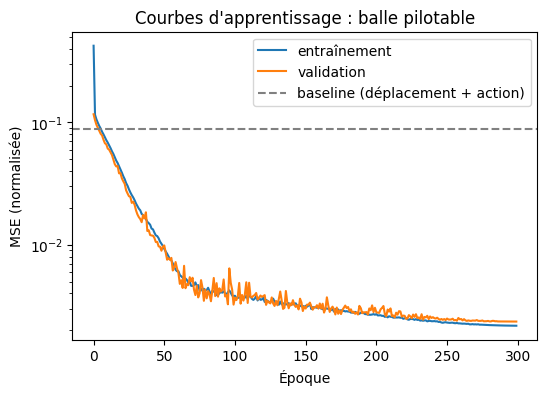

In [ ]:
def baseline_displacement(X):
    """Baseline physique : dernier déplacement + action (ignore les murs et la vitesse max)."""
    last_disp = X[:, 2*K - 2 : 2*K] - X[:, 2*K - 4 : 2*K - 2]
    action = X[:, 2*K : 2*K + 2]
    return last_disp + action

# MSE de la baseline sur la validation, dans la même échelle normalisée
baseline_mse = np.mean(((baseline_displacement(X_val) - Y_val) / model.y_std.numpy()) ** 2)
print(f"MSE normalisée de la baseline : {baseline_mse:.5f}")

plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="entraînement")
plt.plot(history["val"], label="validation")
plt.axhline(baseline_mse, color="gray", linestyle="--", label="baseline (déplacement + action)")
plt.yscale("log")
plt.xlabel("Époque"); plt.ylabel("MSE (normalisée)")
plt.legend(); plt.title("Courbes d'apprentissage : balle pilotable")
plt.show()

Évaluation à un pas

Cette fois, on distingue trois situations : la balle se déplace librement, elle est limitée par la vitesse maximale, ou elle est près d’un rebond.

In [ ]:
X_test, Y_test, nb_test = data["test"]

pred_model = model.predict_displacement(X_test)
pred_base = baseline_displacement(X_test)

err_model = np.linalg.norm(pred_model - Y_test, axis=1)
err_base = np.linalg.norm(pred_base - Y_test, axis=1)

# Saturation : la vitesse aurait dépassé V_MAX sans la limitation
saturated = np.linalg.norm(pred_base, axis=1) > V_MAX
groups = {
    "Mouvement libre": ~nb_test & ~saturated,
    "Vitesse saturée": ~nb_test & saturated,
    "Autour des rebonds": nb_test,
}

print(f"{'':22s} {'Part':>6s} {'Réseau':>10s} {'Baseline':>10s}")
for name, mask in groups.items():
    print(f"{name:22s} {mask.mean():6.1%} {err_model[mask].mean():10.2e} {err_base[mask].mean():10.2e}")
print(f"{'Tous les exemples':22s} {'100%':>6s} {err_model.mean():10.2e} {err_base.mean():10.2e}")

                         Part     Réseau   Baseline
Mouvement libre         81.5%   2.01e-04   4.13e-17
Vitesse saturée          6.1%   1.36e-03   2.03e-03
Autour des rebonds      12.5%   3.29e-03   2.08e-02
Tous les exemples        100%   6.57e-04   2.72e-03


### Interprétation de l'erreur à un pas sur le test

Le modèle reçoit les 3 dernières positions de la balle et l'action appliquée, et prédit le déplacement
suivant. On compare son erreur moyenne à celle de la baseline physique « dernier déplacement + action »,
qui ignore les murs et la limitation de vitesse. Les exemples sont séparés en trois situations.

| Situation | Part | Réseau | Baseline |
|---|---|---|---|
| Mouvement libre | 81,5 % | 2,01e-04 | 4,13e-17 |
| Vitesse saturée | 6,1 % | 1,36e-03 | 2,03e-03 |
| Autour des rebonds | 12,5 % | 3,29e-03 | 2,08e-02 |
| Tous les exemples | 100 % | 6,57e-04 | 2,72e-03 |

**Mouvement libre.** La baseline est exacte. L'erreur du réseau reste inférieure à 1 % d'un pas,
comme à l'étape 1 : le modèle a appris l'effet d'une poussée sur une balle en mouvement.

**Rebonds.** Le réseau est environ 6 fois plus précis que la baseline : il a appris la réflexion sur les
murs en présence d'actions. Son erreur est toutefois environ 5 fois plus élevée qu'à l'étape 1 (en absence d'action), car les
rebonds se combinent maintenant avec des vitesses variables et des poussées.

**Vitesse saturée.** Le réseau ne fait que légèrement mieux que la baseline. Cette situation est rare
(6 % des exemples), et la limitation de la norme de la vitesse est une opération moins simple à
représenter pour un réseau à ReLU que la réflexion sur un mur.

Au total, le modèle a appris l'essentiel de la dynamique, mais il est moins précis qu'à l'étape 1
dans les situations difficiles. CE qui me paraît normal vu la différence de complexité.

In [ ]:
def rollout_model(model, init_context, action_seq):
    """Le modèle imagine la trajectoire produite par une suite d'actions donnée."""
    context = init_context.copy()                   # forme (K, 2)
    predicted = []
    for action in action_seq:
        x = np.concatenate([context.flatten(), action])[None, :]   # forme (1, 2K+2)
        next_pos = context[-1] + model.predict_displacement(x)[0]
        predicted.append(next_pos)
        context = np.vstack([context[1:], next_pos])
    return np.array(predicted)

def rollout_baseline(init_context, action_seq):
    """Baseline : physique sans murs ni vitesse maximale."""
    pos = init_context[-1].copy()
    velocity = init_context[-1] - init_context[-2]
    predicted = []
    for action in action_seq:
        velocity = velocity + action
        pos = pos + velocity
        predicted.append(pos.copy())
    return np.array(predicted)

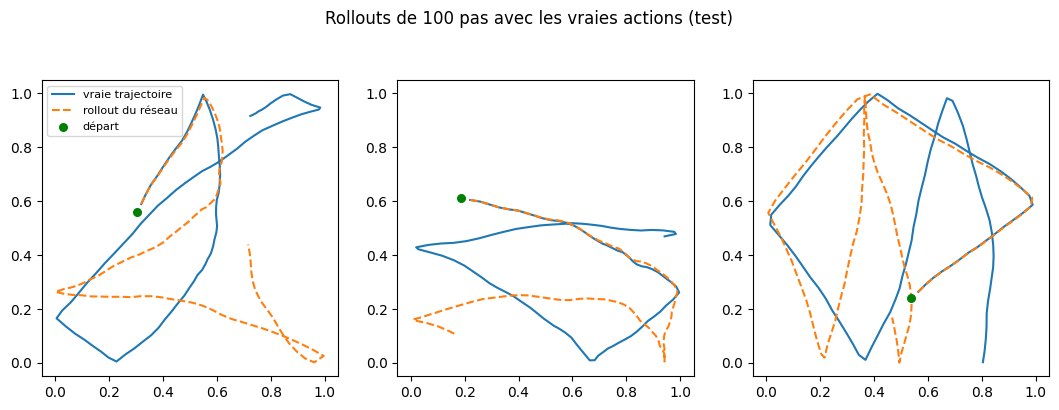

In [ ]:
N_ROLL = 100

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, i in zip(axes, split_indices["test"][:3]):
    positions, actions, _ = trajectories[i]
    # actions[K-1] mène de positions[K-1] à positions[K] : c'est la première action du rollout
    action_seq = actions[K - 1 : K - 1 + N_ROLL]
    true_future = positions[K : K + N_ROLL]
    pred_future = rollout_model(model, positions[:K], action_seq)

    ax.plot(*true_future.T, label="vraie trajectoire", lw=1.5)
    ax.plot(*pred_future.T, "--", label="rollout du réseau", lw=1.5)
    ax.scatter(*positions[K - 1], c="green", s=30, zorder=5, label="départ")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect("equal")
axes[0].legend(fontsize=8)
plt.suptitle(f"Rollouts de {N_ROLL} pas avec les vraies actions (test)")
plt.show()

Horizon  10 pas | réseau 0.010 | baseline 0.069
Horizon  50 pas | réseau 0.161 | baseline 1.903
Horizon 100 pas | réseau 0.376 | baseline 3.631


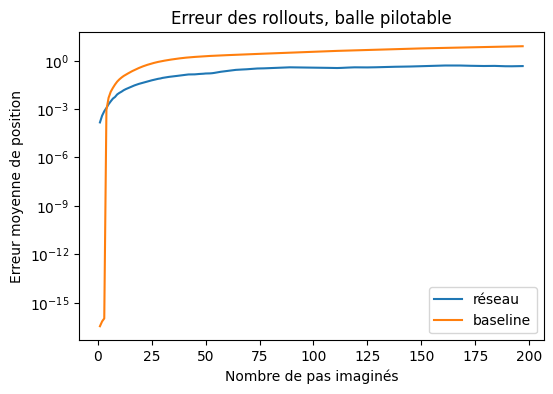

In [ ]:
n_roll = N_STEPS - K
err_roll_model, err_roll_base = [], []

for i in split_indices["test"]:
    positions, actions, _ = trajectories[i]
    action_seq = actions[K - 1 :]
    true_future = positions[K:]
    err_roll_model.append(np.linalg.norm(rollout_model(model, positions[:K], action_seq) - true_future, axis=1))
    err_roll_base.append(np.linalg.norm(rollout_baseline(positions[:K], action_seq) - true_future, axis=1))

err_roll_model = np.mean(err_roll_model, axis=0)
err_roll_base = np.mean(err_roll_base, axis=0)

for h in [10, 50, 100]:
    print(f"Horizon {h:3d} pas | réseau {err_roll_model[h - 1]:.3f} | baseline {err_roll_base[h - 1]:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, n_roll + 1), err_roll_model, label="réseau")
plt.plot(np.arange(1, n_roll + 1), err_roll_base, label="baseline")
plt.yscale("log")
plt.xlabel("Nombre de pas imaginés"); plt.ylabel("Erreur moyenne de position")
plt.legend(); plt.title("Erreur des rollouts, balle pilotable")
plt.show()

### Interprétation des rollouts et passage à la planification

On initialise le modèle avec les 3 premières positions réelles, puis on lui fournit la suite d'actions
réellement appliquées : il doit imaginer la trajectoire qui en résulte.

| Horizon | Réseau | Baseline |
|---|---|---|
| 10 pas | réseau 0.010 | baseline 0.069
|  50 pas | réseau 0.161 | baseline 1.903
| 100 pas | réseau 0.376 | baseline 3.631

**Le modèle est fiable à court terme.** Pendant les 20 à 40 premiers pas, les rollouts suivent bien
la vraie trajectoire.

**Il décroche ensuite, souvent après un rebond.** Une petite erreur de position modifie le moment ou
l'existence d'un rebond. Les actions suivantes, qui sont celles de la vraie trajectoire, s'appliquent
alors à une balle allant dans une autre direction, et l'écart s'amplifie rapidement.

**Ce n'est pas bloquant pour la suite(je pense mdr).** La planification ne s'appuie pas sur des rollouts
longs. À chaque pas, l'agent imagine des suites d'actions sur un horizon court (une dizaine de pas),
applique la première action dans l'environnement réel, observe la nouvelle position, puis recommence.
Le modèle repart donc toujours d'une position réelle, et ses erreurs ne s'accumulent pas au-delà de
l'horizon de planification. C'est donc sa précision sur une dizaine de pas qui compte.

**Démarche.** Plutôt que d'améliorer le modèle à l'aveugle, je vais tester directement s'il est suffisant
pour planifier. Si l'agent atteint les cibles, le modèle est adapté à la tâche, et ses améliorations
pourront être étudiées comme expériences complémentaires. Sinon, la performance de planification
fournira une mesure concrète pour comparer différentes versions du modèle.

# PLANIFICATION

## Planification : amener la balle vers une cible

### L'idée
Jusqu'ici, le modèle a appris à prédire la conséquence d'une action : où va la balle si on lui donne
une certaine poussée. On l'utilise maintenant pour **agir** : une cible est placée dans la boîte, et un
agent doit y amener la balle en la poussant légèrement à chaque pas, en au plus 100 pas.

La difficulté vient de l'**inertie** : la balle a de l'élan, et une poussée ne modifie sa trajectoire
que progressivement. Pousser simplement vers la cible conduit souvent à la dépasser. L'agent doit donc
anticiper, par exemple en freinant avant d'arriver.

### Comment l'agent choisit son action
À chaque pas, l'agent planifie « en imagination » avec son world model :
1. il tire au hasard 500 suites de poussées, chacune sur un horizon de 10 pas ;
2. pour chaque suite, il prédit avec le modèle la trajectoire de la balle qui en résulterait ;
3. il attribue à chaque suite un **coût** : la distance moyenne entre la balle imaginée et la cible ;
4. il applique dans l'environnement réel **uniquement la première action** de la suite de coût minimal ;
5. il observe la nouvelle position réelle de la balle, puis recommence au pas suivant.

Cette méthode s'appele le *random shooting*, dans un schéma de *Model Predictive Control* (MPC).
Replanifier à chaque pas à partir de la position réelle permet de corriger les erreurs du modèle :
celles-ci ne s'accumulent jamais au-delà de l'horizon de planification.

### Lien avec l'architecture de LeCun ( et oui je fais tout ça pour mettre son idée à l'épreuve )
Voici les modules d'un agent autonome tel que décrit par LeCun (JEPA 2022) et qu'on retrouve dans cette section du projet :
- **le world model**, qui prédit l'état suivant à partir de l'état et de l'action ;
- **le module de coût**, ici la distance à la cible ;
- **l'acteur**, qui cherche les actions minimisant le coût prédit par le world model.

Seul l'encodeur est absent : l'agent observe directement les positions de la balle.
Il sera introduit à l'étape 3, lorsque les observations deviendront des images.(j'ai hâte...)

### Protocole d'évaluation
Quatre agents jouent exactement les mêmes 50 épisodes (positions de départ, vitesses et cibles
identiques). Un épisode est réussi si la balle passe à moins de 0,05m de distance de la cible.

| Agent | Stratégie | Rôle |
|---|---|---|
| Aléatoire | Pousse au hasard (quelle honte) | Borne inf |
| Glouton | Pousse toujours en direction de la cible, sans anticiper | Montre l'intérêt de la planification |
| World model | Planifie avec le modèle appris, à partir des positions observées | Agent évalué |
| Oracle | Planifie avec la vraie physique, en connaissant la vraie vitesse | Borne haute de la méthode |

On mesure le **taux de réussite** et le **nombre moyen de pas** nécessaires pour atteindre la cible.
Si l'agent world model s'approche des performances de l'oracle, le modèle appris est suffisamment
précis pour planifier.

In [ ]:
# l'environnement
def env_step(pos, vel, action, v_max=V_MAX, low=0.0, high=1.0):
    """
    Fait avancer une ou plusieurs balles d'un pas (vraie physique).
    pos, vel, action : tableaux de forme (2,) ou (N, 2).
    """
    # 1. La poussée modifie la vitesse
    vel = vel + action

    # 2. Limitation de la norme de la vitesse (même direction, norme plafonnée)
    speed = np.linalg.norm(vel, axis=-1, keepdims=True)
    vel = np.where(speed > v_max, vel * v_max / np.maximum(speed, 1e-12), vel)

    # 3. Déplacement
    pos = pos + vel

    # 4. Rebonds : réflexion de la position et inversion de la vitesse, axe par axe
    below, above = pos < low, pos > high
    pos = np.where(below, 2 * low - pos, pos)
    pos = np.where(above, 2 * high - pos, pos)
    vel = np.where(below | above, -vel, vel)

    return pos, vel

In [ ]:
def imagine_with_model(model, context, action_seqs):
    """
    Le modèle imagine N trajectoires en parallèle.
    context : (K, 2), les K dernières positions réelles.
    action_seqs : (N, H, 2), N suites de H actions.
    Retourne : (N, H, 2), les positions imaginées.
    """
    N, H, _ = action_seqs.shape
    ctx = np.repeat(context[None], N, axis=0)          # le même contexte pour les N suites : (N, K, 2)
    traj = np.zeros((N, H, 2))
    for h in range(H):
        X = np.concatenate([ctx.reshape(N, -1), action_seqs[:, h]], axis=1)   # (N, 2K + 2)
        next_pos = ctx[:, -1] + model.predict_displacement(X)
        traj[:, h] = next_pos
        ctx = np.concatenate([ctx[:, 1:], next_pos[:, None]], axis=1)          # fenêtre glissante
    return traj

def imagine_with_simulator(pos, vel, action_seqs):
    """L'oracle imagine N trajectoires avec la vraie physique."""
    N, H, _ = action_seqs.shape
    p, v = np.repeat(pos[None], N, axis=0), np.repeat(vel[None], N, axis=0)
    traj = np.zeros((N, H, 2))
    for h in range(H):
        p, v = env_step(p, v, action_seqs[:, h])
        traj[:, h] = p
    return traj

In [ ]:
# le planificateur

N_SEQ = 500     # nombre de suites d'actions imaginées à chaque pas
HORIZON = 10    # nombre de pas imaginés par suite

def plan_action(imagine_fn, target, rng):
    """Random shooting : renvoie la première action de la meilleure suite imaginée."""
    action_seqs = rng.uniform(-A_MAX, A_MAX, size=(N_SEQ, HORIZON, 2))
    traj = imagine_fn(action_seqs)                                     # (N_SEQ, HORIZON, 2)
    costs = np.linalg.norm(traj - target, axis=-1).mean(axis=1)        # distance moyenne à la cible
    return action_seqs[np.argmin(costs), 0]

In [ ]:
# les 4 agents ( les 4 mousquetaires )
def agent_random(context, pos, vel, target, rng):
    """Borne basse : action aléatoire."""
    return rng.uniform(-A_MAX, A_MAX, size=2)

def agent_greedy(context, pos, vel, target, rng):   #glouton
    """Pousse toujours en direction de la cible, sans tenir compte de l'élan de la balle."""
    direction = target - context[-1]
    return A_MAX * direction / max(np.linalg.norm(direction), 1e-12)

def agent_model(context, pos, vel, target, rng):
    """Planifie avec le world model appris : n'utilise que les positions."""
    return plan_action(lambda seqs: imagine_with_model(model, context, seqs), target, rng)

def agent_oracle(context, pos, vel, target, rng):
    """Borne haute : planifie avec la vraie physique (connaît la vraie vitesse)."""
    return plan_action(lambda seqs: imagine_with_simulator(pos, vel, seqs), target, rng)

In [ ]:
MAX_STEPS = 100
EPS = 0.05

def make_episodes(n, rng):
    """Tire n situations de départ : position, vitesse et cible."""
    episodes = []
    for _ in range(n):
        pos = rng.uniform(0.1, 0.9, size=2)
        angle = rng.uniform(0.0, 2.0 * np.pi)
        vel = V_INIT * np.array([np.cos(angle), np.sin(angle)])
        target = rng.uniform(0.1, 0.9, size=2)
        episodes.append((pos, vel, target))
    return episodes

def run_episode(agent, start, rng):
    """Fait jouer un agent sur un épisode. Renvoie (succès, nombre de pas, positions, cible)."""
    pos, vel, target = start
    history = [pos.copy()]
    for _ in range(K - 1):                        # mise en route : K positions pour le contexte
        pos, vel = env_step(pos, vel, np.zeros(2))
        history.append(pos.copy())

    for t in range(MAX_STEPS):
        if np.linalg.norm(pos - target) < EPS:
            return True, t, np.array(history), target
        context = np.array(history[-K:])
        action = agent(context, pos, vel, target, rng)
        pos, vel = env_step(pos, vel, action)
        history.append(pos.copy())

    return np.linalg.norm(pos - target) < EPS, MAX_STEPS, np.array(history), target

In [ ]:
N_EPISODES = 50
episodes = make_episodes(N_EPISODES, np.random.default_rng(123))

agents = {
    "Aléatoire": agent_random,
    "Glouton": agent_greedy,
    "World model": agent_model,
    "Oracle (vrai simulateur)": agent_oracle,
}

results = {}
for name, agent in agents.items():
    plan_rng = np.random.default_rng(SEED)
    outcomes = [run_episode(agent, ep, plan_rng) for ep in episodes]
    results[name] = outcomes
    successes = np.array([o[0] for o in outcomes])
    steps = np.array([o[1] for o in outcomes])
    mean_steps = steps[successes].mean() if successes.any() else float("nan")
    print(f"{name:26s} | réussite {successes.mean():6.1%} | pas moyens (si réussite) {mean_steps:5.1f}")

Aléatoire                  | réussite  36.0% | pas moyens (si réussite)  52.9
Glouton                    | réussite  54.0% | pas moyens (si réussite)  26.2
World model                | réussite 100.0% | pas moyens (si réussite)  17.1
Oracle (vrai simulateur)   | réussite 100.0% | pas moyens (si réussite)  18.0


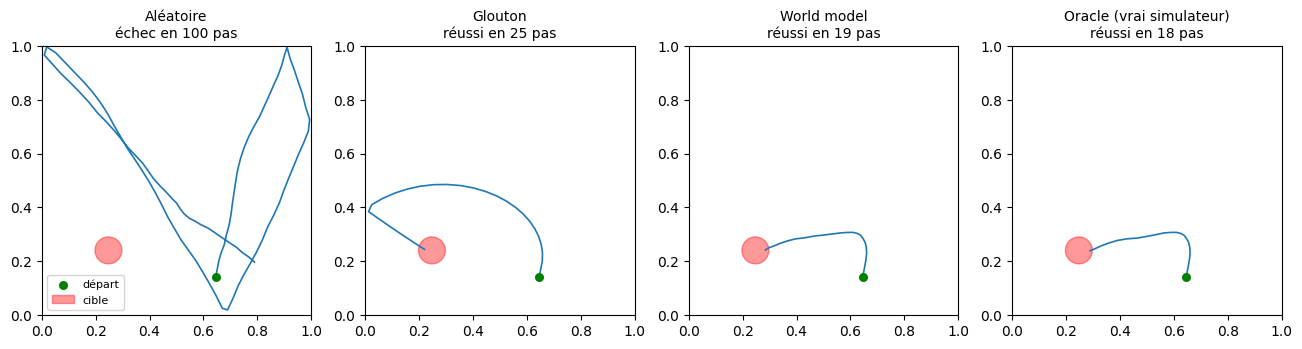

In [ ]:
ep_id = 0
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (name, outcomes) in zip(axes, results.items()):
    success, steps, history, target = outcomes[ep_id]
    ax.plot(*history.T, lw=1.2)
    ax.scatter(*history[0], c="green", s=30, zorder=5, label="départ")
    ax.add_patch(plt.Circle(target, EPS, color="red", alpha=0.4, label="cible"))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_title(f"{name}\n{'réussi' if success else 'échec'} en {steps} pas", fontsize=10)
axes[0].legend(fontsize=8)
plt.show()

### Résultats de la planification


| Agent | Taux de réussite | Pas moyens (si réussite) |
|---|---|---|
| Aléatoire | 36,0 % | 52,9 |
| Glouton | 54,0 % | 26,2 |
| World model | 100,0 % | 17,1 |
| Oracle (vrai simulateur) | 100,0 % | 18,0 |

**Le world model permet une planification aussi efficace que la vraie physique.** L'agent qui planifie
avec le modèle appris atteint la cible dans tous les épisodes, en un nombre de pas comparable à
l'oracle. L'écart de durée observé (17,1 contre 18,0 pas) n'est pas significatif : il reste faible,
sur seulement 50 épisodes, avec un planificateur stochastique.

**Les erreurs de prédiction à long terme ne gênent pas la planification.** Bien que les rollouts du
modèle divergent après plusieurs dizaines de pas, l'agent replanifie à chaque pas à partir de la
position réelle de la balle, sur un horizon de 10 pas seulement, où le modèle reste précis.

**Anticiper est nécessaire.** L'agent glouton, qui pousse toujours vers la cible, échoue dans près de
la moitié des épisodes : la balle conserve son élan, dépasse la cible et décrit de larges détours.
Les agents qui planifient anticipent cet élan, en freinant la balle avant de se diriger vers la cible.
Sur l'épisode représenté, les trajectoires du world model et de l'oracle sont presque identiques,
ce qui montre que le modèle conduit aux mêmes décisions que la vraie physique.

**Limite.** Le critère de réussite est permissif : la balle doit seulement passer à moins de 0,05 de la
cible. Les deux agents qui planifient atteignent 100 % de réussite, ce qui ne permet plus de les
différencier. Une tâche plus exigeante est nécessaire pour mesurer finement la qualité du modèle.

## Vue d'ensemble : world model et planification

### Phase 1: Apprendre le world model
Les données sont générées avec des **actions aléatoires** : le modèle ne décide rien, il observe
seulement les conséquences des actions.

```text
  3 dernières positions  ─┐
   p(t-2), p(t-1), p(t)   │      ┌──────────────────┐      déplacement      ┌───────────┐
                          ├────► │   World model    │ ──── prédit Δp̂ ─────► │           │
  action a(t)             │      │  (MLP, θ appris) │                       │  Loss MSE │ ──► mise à jour de θ
  (aléatoire)            ─┘      └──────────────────┘                       │           │
                                                                            └─────▲─────┘
  simulateur  ───────────────────── vrai déplacement Δp = p(t+1) − p(t) ──────────┘
```

### Phase 2 : Planifier avec le world model
Les poids du modèle sont **figés**. À chaque pas, l'agent l'utilise pour imaginer les conséquences
de différentes actions, puis agit dans le monde réel.

```text
                      ┌───────────────────────────── AGENT (random shooting) ─────────────────────────────┐
                      │                                                                                   │
  positions réelles ──┼─► 1. tirer 500 suites de 10 actions au hasard                                     │
  p(t-2), p(t-1), p(t)│                     │                                                             │
                      │                     ▼                                                             │
                      │   2. imaginer chaque trajectoire ◄──────► World model (figé)                      │
                      │      p̂(t+1), …, p̂(t+10)               « où va la balle si je fais a ? »           │
                      │                     │                                                             │
                      │                     ▼                                                             │
  cible ──────────────┼─► 3. coût = distance moyenne entre la trajectoire imaginée et la cible            │
                      │                     │                                                             │
                      │                     ▼                                                             │
                      │   4. garder la suite de coût minimal et renvoyer sa PREMIÈRE action a*(t)         │
                      └─────────────────────┬─────────────────────────────────────────────────────────────┘
                                            │
                                            ▼
                               ┌─────────────────────────┐
                               │      Monde réel         │
                               │      (simulateur)       │
                               └────────────┬────────────┘
                                            │ nouvelle position réelle p(t+1)
                                            └──────────► on recommence au pas suivant
```

### À retenir
- **Le world model comprend** : il répond à la question « que se passe-t-il si je fais telle action ? ».
- **L'agent décide** : il utilise ces réponses pour choisir l'action qui rapproche la balle de la cible.
- **Seule la MSE entraîne le modèle.** Le coût de planification sert uniquement à choisir les actions :
  il ne modifie pas les poids.
- **Replanifier à chaque pas** depuis la position réelle empêche les erreurs du modèle de s'accumuler.

## Conclusion de l'étape 2

### Objectif
Apprendre un world model qui prédit l'effet d'une action sur la balle, puis l'utiliser pour planifier
des actions qui amènent la balle vers une cible.

### Résultats

**Le modèle a appris l'effet des actions.** À partir des 3 dernières positions de la balle et de
l'action appliquée, il prédit le déplacement suivant :
- en mouvement libre (81,5 % des exemples), avec une erreur inférieure à 1 % d'un pas ;
- autour des rebonds (12,5 % des exemples), avec une erreur environ 6 fois plus faible que la baseline
  physique « dernier déplacement + action », qui ignore les murs.

**Il est fiable à court terme.** Ses rollouts suivent la vraie trajectoire pendant plusieurs dizaines
de pas, puis divergent, généralement après un rebond.

**Il permet de planifier aussi bien que la vraie physique.** Utilisé dans un planificateur de type MPC
(random shooting sur un horizon de 10 pas, replanification à chaque pas), il amène la balle sur la
cible dans 100 % des épisodes, en 17,1 pas en moyenne, contre 100 % de réussite par épisode et 18,0 pas pour l'oracle qui
planifie avec la vraie physique. Un agent qui pousse simplement vers la cible ne réussit que dans 54 %
des épisodes, faute d'anticiper l'élan de la balle.

**La planification compense les limites du modèle.** Comme l'agent repart à chaque pas de la position
réelle et n'imagine qu'un horizon court, les erreurs de prédiction à long terme n'ont pas d'impact
sur sa réussite.

### Limites
- Autour des rebonds, le modèle actionné est environ 5 fois moins précis qu'à l'étape 1 : les rebonds se
  combinent désormais avec des vitesses variables et des poussées.
- La limitation de la vitesse maximale est mal apprise, en partie à cause de la rareté du cas dans les données (6 % des exemples)
  et plus difficile à représenter pour un réseau activé par ReLU.
- Le critère de réussite est permissif (passer à moins de 0,05 de la cible) : il ne permet pas de
  distinguer plus précisément le world model de l'oracle, qui atteignent tous deux 100 %.


L'ensemble des résultats viennent d'une seul seed ( par soucie de reproductivité ).

### Lien avec l'architecture de LeCun
Cette étape met en place l'essentiel de l'agent autonome décrit par LeCun (2022) :
- un **world model**, qui prédit les conséquences des actions ;
- un **module de coût**, la distance à la cible ;
- un **acteur**, qui choisit les actions minimisant ce coût en imaginant leurs conséquences.

Seul l'**encodeur** manque : l'agent observe directement les positions de la balle. Il sera introduit
à l'étape 3 avec la JEPA, lorsque l'agent observera des images et prédira dans un espace latent appris.